# Notebook

## Import das bibliotecas necessárias

In [4]:
!pip install segmentation-models-pytorch
!pip install timm

In [ ]:
import cv2
import torch
import kagglehub
import numpy as np
import pandas as pd

# from torch import nn, optim
# import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision.transforms import v2
import torchvision.transforms.functional as TF
from torchvision.io import decode_image
from torchvision.io.image import ImageReadMode
from torch.utils.data import random_split
from torch.utils.data import Subset

from matplotlib import pyplot as plt
import matplotlib.image as mpimg
# import matplotlib.patches as patches

from tqdm import tqdm

import os
from glob import glob
# import json

from scipy import ndimage

# import segmentation_models_pytorch as smp
# from skimage import morphology, measure

DEVICE = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
DEVICE

'cpu'

## Dataset

Definindo o caminho do dataset de input

In [6]:
#### SE FOR RODAR NO KAGGLE
# INPUT_DIR = "/kaggle/input/guilhermecastilho222/chest-xray-weak-labels-selfsupervised-learning/output/"
#### SE QUISER RODAR LOCAL OU NO COLAB
INPUT_DIR = kagglehub.dataset_download("guilhermecastilho222/chest-xray-weak-labels-selfsupervised-learning")
INPUT_DIR = os.path.join(INPUT_DIR, "output")

# VERSÃO ORIGINAL E FILTRO QC V2

Definição das funções que geram as weak labels e que calculam o QC (Quality Control).

In [7]:
def generate_weak_mask(img_path):
    # Carrega a imagem e redimenciona
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    img = cv2.resize(img, (512, 512))
    # "Estoura" pixels extremos para que não entrem na máscara
    img[img < 50] = 255 
    img[img > 180] = 255
    
    # Equalização + suavização
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    I = clahe.apply(img)
    I = cv2.GaussianBlur(I, (7,7), 0)
    
    for ang in np.arange(0, 151, 30):
        se = np.zeros((15, 15), np.uint8)
        cv2.ellipse(se, (15//2, 15//2), (15//2, 1), ang, 0, 360, 1, -1)
        I_supp = cv2.morphologyEx(I, cv2.MORPH_OPEN, se)
        I = cv2.min(I, I_supp)
        
    # Inverte para que opacidades fiquem claras
    I_inv = cv2.normalize(255 - I, None, 0, 255, cv2.NORM_MINMAX)

    # Filtro bilateral
    I_inv_bilateral = cv2.bilateralFilter(I_inv.astype(np.uint8), d=-1, sigmaColor=0.25*255, sigmaSpace=15)

    # Aplica um treshold simples
    _, bw = cv2.threshold(I_inv_bilateral, 127, 255, cv2.THRESH_BINARY)
    
    # Limpa regiões fora dos pulmões
    # remove um pequeno pedaço do topo e das laterais que não incluem o pulmão (geralmente)
    bw[:40, :], bw[:, -70:], bw[:, :70] = 0,0, 0
    
    # Morfologia para suavizar
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9,9))
    bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, kernel)
    bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, kernel)
    
    # Mantém regiões internas
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(bw)
    mask_out = np.zeros_like(bw)
    
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        x,y = stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP]
        wc,hc = stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]

        # Descarta regiões no topo e muito pequenas
        if area > 500 and y > 39:
            mask_out[labels == i] = 255

    # Remove objetos pequenos (geralmente ombro ou parte da silhueta lateral)
    mask_out = morphology.remove_small_objects(mask_out.astype(bool), min_size=5000)
    
    # Volta ao tamanho original
    mask_out = mask_out.astype(np.uint8)
    mask_out = cv2.resize(mask_out, (w, h))
    
    return torch.from_numpy(mask_out).unsqueeze(0).float()

# # # Função QC
# # def qc_score(mask, min_area=0.04, max_area=0.3, min_ecc=0.4, max_ecc=0.98, max_aspect=0.35, num_obj=2):
#     # props = measure.regionprops(measure.label(mask[0]))
#     # # Apenas os 2 maiores objetos (idealmente apenas pulmões)
#     # props = sorted(props, key=lambda x: x.area, reverse=True)[:2]

#     # H, W = mask[0].shape

#     # scores = 0

#     # try:
#     #     biggest_area = props[0].area
#     # except:
#     #     print(f"Mascara problemática, Nº de objetos nela: {len(props)}")
#     #     return 0

#     # for p in props:
#     #     lung_scores = list()
#     #     # Área relativa
#     #     area_frac = p.area / (H * W)
#     #     if area_frac < min_area:
#     #         lung_scores.append(area_frac / min_area)
#     #     elif area_frac > max_area:
#     #         lung_scores.append(max_area / area_frac)
#     #     else:
#     #         lung_scores.append(1.0)

#     #     # Eccentricidade
#     #     ecc = p.eccentricity
#     #     if ecc < min_ecc:
#     #         lung_scores.append(ecc / min_ecc)
#     #     elif ecc > max_ecc:
#     #         lung_scores.append(max_ecc / ecc)
#     #     else:
#     #         lung_scores.append(1.0)

#     #     # Solidity
#     #     lung_scores.append(p.solidity)

#     #     # Extent
#     #     lung_scores.append(p.extent)

#     #     # Aspect ratio
#     #     minr, minc, maxr, maxc = p.bbox
#     #     bbox_h = maxr - minr
#     #     bbox_w = maxc - minc
#     #     aspect = max(bbox_h / (bbox_w + 1e-9), bbox_w / (bbox_h + 1e-9))
#     #     if aspect > max_aspect:
#     #         lung_scores.append(max_aspect / aspect)
#     #     else:
#     #         lung_scores.append(1.0)

#     #     # Nº de objetos
#     #     n_obj = len(props)
#     #     if n_obj > num_obj:
#     #         lung_scores.append(1 / n_obj)
#     #     else:
#     #         lung_scores.append(n_obj / num_obj)
       
#     #     # Soma o score do pulmão ao score final ponderado pela diferença de tamanho entre pulmões 
#     #     scores += np.mean(lung_scores) * (p.area / biggest_area)

#     # return scores / 2 # Média dos pulmões

# def qc_score(mask, min_area=0.08, max_area=0.18, min_ecc=0.85, max_ecc=0.97, min_solidity=0.8, max_solidity=0.97, min_aspect=0.35, max_aspect=0.65, num_obj=2):
    
#     mask_np = mask[0].cpu().numpy() > 0 if torch.is_tensor(mask) else (mask[0] > 0)
#     mask_2d= morphology.remove_small_objects(mask_np, min_size=50)
#     props = measure.regionprops(measure.label(mask_2d))
#     # TODO: UTILIZAR O NÚMERO DE OBJETOS NO CALCULO DO SCORE
#     # Nº de objetos
#     # n_obj = len(props)
#     # if n_obj > num_obj:
#     #     n_obj_score = 1 / n_obj #max(0.0, 1.0 - (total_objs - num_obj) * 0.25)
#     # else:
#     #     n_obj_score = n_obj / num_obj
        
#     # Apenas os 2 maiores objetos (idealmente apenas pulmões)
#     props = sorted(props, key=lambda x: x.area, reverse=True)[:2]

#     H, W = mask_2d.shape

#     scores = 0

#     try:
#         biggest_area = props[0].area
#     except:
#         # print(f"Mascara problemática, Nº de objetos nela: {len(props)}")
#         return 0

#     for p in props:
#         lung_scores = list()
#         # Área relativa
#         area_frac = p.area / (H * W)
#         if area_frac < min_area * 0.7:
#             lung_scores.append(0)
#         elif area_frac < min_area:
#             lung_scores.append(area_frac / min_area / 2)
#         elif area_frac > max_area * 1.4:
#             lung_scores.append(0)
#         elif area_frac > max_area:
#             lung_scores.append(max_area / area_frac / 2)
#         else:
#             lung_scores.append(1)

#         # Eccentricidade
#         ecc = p.eccentricity
#         if ecc < min_ecc * 0.8:
#             lung_scores.append(0)
#         elif ecc < min_ecc:
#             lung_scores.append(ecc)
#         elif ecc > max_ecc:
#             lung_scores.append(max_ecc - 0.15)
#         else:
#             lung_scores.append(1.0)

#         # Solidity
#         solidity=p.solidity
#         if solidity < min_solidity * 0.75:
#             lung_scores.append(0)
#         elif solidity < min_solidity - 0.05:
#             lung_scores.append(solidity * 0.75)
#         elif solidity < min_solidity:
#             lung_scores.append(solidity)
#         elif solidity > max_solidity:
#             lung_scores.append(solidity - 0.1)
#         else:
#             lung_scores.append(1.0)
            
#         # # Extent
#         # lung_scores.append(p.extent)

#         # Aspect ratio
#         minr, minc, maxr, maxc = p.bbox
#         bbox_h = maxr - minr
#         bbox_w = maxc - minc
#         aspect = bbox_w / (bbox_h + 1e-9)
#         if aspect < min_aspect * 0.8:
#             lung_scores.append(0)
#         elif aspect < min_aspect:
#             lung_scores.append(aspect / min_aspect * 0.75)
#         elif aspect > 0.94:
#             lung_scores.append(0)
#         elif aspect > 0.82:
#             lung_scores.append(max_aspect / aspect * 0.8)
#         elif aspect > max_aspect:
#             lung_scores.append(max_aspect / aspect * 0.9)
#         else:
#             lung_scores.append(1)

#         # Soma o score do pulmão ao score final ponderado pela diferença de tamanho entre pulmões 
#         scores += np.mean(lung_scores) * (p.area / biggest_area)

#     return scores / 2 # Média dos pulmões

# FILTRO QC V3

In [8]:
def _extract_thorax_interior(img_512: np.ndarray) -> np.ndarray:
    """Isola o interior do tronco para eliminar 100% do ar externo e da interface pele-ar."""
    blur = cv2.GaussianBlur(img_512, (11, 11), 0)
    # Limiar baixo via Otsu na metade inferior/central ou percentil para separar corpo do fundo escuro
    otsu_val, _ = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    body_thresh = max(15, min(int(otsu_val * 0.45), 75))
    body = (blur > body_thresh).astype(np.uint8)

    # Mantém apenas o maior componente (o paciente) e preenche os pulmões internos
    num_l, labels, stats, _ = cv2.connectedComponentsWithStats(body)
    if num_l > 1:
        largest_idx = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        body = (labels == largest_idx).astype(np.uint8)

    body = ndimage.binary_fill_holes(body).astype(np.uint8)

    # Erosão de ~22px (~4.3% da largura) remove pele, tecido subcutâneo lateral e interface ar-pele
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (45, 45))
    thorax_interior = cv2.erode(body, erode_kernel, iterations=1)

    # Fallback caso a erosão seja agressiva demais em imagens muito recortadas
    if thorax_interior.sum() < 0.20 * img_512.size:
        erode_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
        thorax_interior = cv2.erode(body, erode_kernel, iterations=1)

    return thorax_interior


def generate_weak_mask(img_path: str) -> torch.Tensor:
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    img_512 = cv2.resize(img, (512, 512), interpolation=cv2.INTER_AREA)

    # 1. Máscara segura do interior do tronco
    thorax_mask = _extract_thorax_interior(img_512)

    # 2. Realce local + supressão de costelas com kernel maior (27px)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    I = clahe.apply(img_512)
    I = cv2.GaussianBlur(I, (5, 5), 0)

    for ang in np.arange(0, 151, 30):
        se = np.zeros((27, 27), np.uint8)
        cv2.ellipse(se, (13, 13), (13, 1), int(ang), 0, 360, 1, -1)
        I_supp = cv2.morphologyEx(I, cv2.MORPH_OPEN, se)
        I = cv2.min(I, I_supp)

    # 3. Filtro bilateral antes da inversão para preservar bordas mediastinais/diafragmáticas
    I_bilat = cv2.bilateralFilter(I, d=9, sigmaColor=35, sigmaSpace=15)
    I_inv = 255 - I_bilat

    # 4. Limiarização adaptativa calculada APENAS dentro do interior do tronco
    # (exclui ossos muito densos que ficaram < 40 após inversão)
    valid_pixels = I_inv[(thorax_mask > 0) & (I_inv > 35)]
    if len(valid_pixels) > 500:
        # Otsu restrito ao interior do tórax separa parênquima aerado de mediastino/diafragma
        otsu_in, _ = cv2.threshold(valid_pixels.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        # Ligeiramente abaixo do Otsu puro para recuperar pulmões parcialmente opacificados
        thresh_val = int(np.clip(otsu_in * 0.92, 70, 195))
    else:
        thresh_val = 127

    bw = ((I_inv >= thresh_val) & (thorax_mask > 0)).astype(np.uint8) * 255

    # Margem superior mínima apenas para pescoço/traqueia alta (20px em 512 = 3.9%)
    bw[:20, :] = 0

    # 5. Refinamento morfológico: fecha vasos hilares sem fundir o mediastino
    open_k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    close_k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (13, 13))
    bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, open_k)
    bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, close_k)

    # 6. Filtragem de componentes por posição e área proporcional
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(bw)
    mask_out = np.zeros_like(bw, dtype=bool)
    min_lung_area = int(0.012 * 512 * 512)  # ~3145 px (permite pulmões assimétricos/menores)

    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        cx, cy = centroids[i]
        # Descarta ruídos, estruturas exclusivamente cervicais (cy < 90) ou subdiafragmáticas (cy > 430)
        if area >= min_lung_area and (90 <= cy <= 430):
            mask_out[labels == i] = True

    mask_out = morphology.remove_small_holes(mask_out, area_threshold=1500)
    mask_out = (mask_out.astype(np.uint8)) * 255
    mask_out = cv2.resize(mask_out, (w, h), interpolation=cv2.INTER_NEAREST)

    return torch.from_numpy(mask_out).unsqueeze(0).float()

In [9]:
def _trapezoid_score(val: float, low_hard: float, low_opt: float, high_opt: float, high_hard: float) -> float:
    """Retorna 1.0 dentro de [low_opt, high_opt], decai linearmente até [low_hard, high_hard] e 0.0 fora."""
    if val <= low_hard or val >= high_hard:
        return 0.0
    if low_opt <= val <= high_opt:
        return 1.0
    if val < low_opt:
        return (val - low_hard) / (low_opt - low_hard + 1e-9)
    return (high_hard - val) / (high_hard - high_opt + 1e-9)


def _score_single_lung(prop, H: int, W: int, side: str) -> float:
    area_frac = prop.area / (H * W)
    sol = prop.solidity
    ecc = prop.eccentricity

    minr, minc, maxr, maxc = prop.bbox
    aspect = (maxc - minc) / ((maxr - minr) + 1e-9)

    perim_norm = prop.perimeter / np.sqrt(H * W)
    circularity = (4.0 * np.pi * prop.area) / (prop.perimeter ** 2 + 1e-9)

    if side == "esq":  # Lado esquerdo da imagem (pulmão direito anatômico)
        s_area = _trapezoid_score(area_frac, 0.040, 0.085, 0.190, 0.230)
        s_sol = _trapezoid_score(sol, 0.730, 0.855, 0.950, 0.980)
        s_ecc = _trapezoid_score(ecc, 0.730, 0.855, 0.945, 0.975)
        s_perim = _trapezoid_score(perim_norm, 0.90, 1.38, 2.08, 2.28)
    else:  # Lado direito da imagem (pulmão esquerdo anatômico)
        s_area = _trapezoid_score(area_frac, 0.025, 0.068, 0.170, 0.260)
        s_sol = _trapezoid_score(sol, 0.640, 0.815, 0.945, 0.980)
        s_ecc = _trapezoid_score(ecc, 0.740, 0.885, 0.965, 0.990)
        s_perim = _trapezoid_score(perim_norm, 0.55, 1.32, 2.08, 2.30)

    s_aspect = _trapezoid_score(aspect, 0.310, 0.380, 0.630, 0.920)
    s_circ = _trapezoid_score(circularity, 0.280, 0.420, 0.680, 0.800)

    # Ponderação guiada pelo inverso do CV (shape invariants pesam mais que área)
    weights = np.array([2.5, 2.5, 1.5, 1.5, 1.0, 1.0])
    scores = np.array([s_sol, s_ecc, s_aspect, s_circ, s_area, s_perim])
    base_score = float(np.sum(weights * scores) / np.sum(weights))

    # Penalização se a máscara encostar na borda externa do frame (vazamento de fundo)
    margin = max(2, int(0.015 * W))
    touches_edge = (minr <= margin) or (maxr >= H - margin) or (minc <= margin) or (maxc >= W - margin)
    if touches_edge:
        base_score *= 0.45

    return base_score


def qc_score(mask) -> float:
    mask_np = mask[0].cpu().numpy() > 0 if torch.is_tensor(mask) else (mask[0] > 0)
    H, W = mask_np.shape

    # Remove ruídos minúsculos proporcionais à resolução (~50px em 256x256)
    min_noise_px = max(16, int(0.0008 * H * W))
    mask_2d = morphology.remove_small_objects(mask_np, min_size=min_noise_px)
    labeled = measure.label(mask_2d)
    props = measure.regionprops(labeled)

    if len(props) == 0:
        return 0.0

    props = sorted(props, key=lambda x: x.area, reverse=True)
    n_obj = len(props)

    # 1. Penalização pela contagem de objetos (ideal = 2)
    if n_obj == 1:
        count_factor = 0.25  # Pulmão único ou fusão mediastinal
    elif n_obj == 2:
        count_factor = 1.0
    else:
        # Penaliza conforme o tamanho relativo dos objetos excedentes
        extra_area = sum(p.area for p in props[2:])
        top2_area = props[0].area + props[1].area + 1e-9
        count_factor = max(0.25, 1.0 - 0.15 * (n_obj - 2) - 1.5 * (extra_area / top2_area))

    if n_obj == 1:
        # Avalia apenas como diagnóstico de falha severa (nunca passará em limiar >= 0.40)
        side = "esq" if props[0].centroid[1] < (W / 2.0) else "dir"
        return float(np.clip(_score_single_lung(props[0], H, W, side) * count_factor, 0.0, 1.0))

    # 2. Ordena os 2 maiores componentes da esquerda para a direita da imagem
    p_esq, p_dir = sorted(props[:2], key=lambda x: x.centroid[1])
    score_esq = _score_single_lung(p_esq, H, W, side="esq")
    score_dir = _score_single_lung(p_dir, H, W, side="dir")
    individual_score = 0.5 * (score_esq + score_dir)

    # 3. Avaliação Global Bilateral (_total) sobre a união dos 2 maiores componentes
    union_mask = (labeled == p_esq.label) | (labeled == p_dir.label)
    union_props = measure.regionprops(union_mask.astype(np.uint8))[0]

    fill_total = union_props.area / (H * W)
    u_minr, u_minc, u_maxr, u_maxc = union_props.bbox
    aspect_total = (u_maxc - u_minc) / ((u_maxr - u_minr) + 1e-9)
    solidity_total = union_props.solidity

    s_fill_tot = _trapezoid_score(fill_total, 0.083, 0.160, 0.345, 0.435)
    s_asp_tot = _trapezoid_score(aspect_total, 0.780, 0.875, 1.325, 1.540)
    s_sol_tot = _trapezoid_score(solidity_total, 0.380, 0.538, 0.680, 0.785)

    global_score = (0.40 * s_sol_tot) + (0.35 * s_asp_tot) + (0.25 * s_fill_tot)

    # 4. Garantia de separação anatômica esquerda/direita (evita 2 pedaços do mesmo lado)
    cx_esq = p_esq.centroid[1] / W
    cx_dir = p_dir.centroid[1] / W
    dx_sep = cx_dir - cx_esq
    sep_factor = 1.0 if (0.20 <= dx_sep <= 0.68 and cx_esq < 0.52 and cx_dir > 0.48) else 0.40

    final_score = (0.65 * individual_score + 0.35 * global_score) * count_factor * sep_factor
    return float(np.clip(final_score, 0.0, 1.0))

# Classe de Dataset e Augmentation

In [10]:
# class SelfSegCXRDataset(Dataset):
#     def __init__(self, dataset_path=INPUT_DIR, image_size=None, augment=None, device=DEVICE):
#         self._path_data = dataset_path
#         self.images_paths = glob(os.path.join(self._path_data, "images", "*.jpg"))
#         self.weak_labels_paths = glob(os.path.join(self._path_data, "weak_labels", "*.png"))

#         self.device = device

#         if image_size:
#             self.resize_image = v2.Resize(size=image_size, interpolation=v2.InterpolationMode.BILINEAR, antialias=True)
#             self.resize_mask = v2.Resize(size=image_size, interpolation=v2.InterpolationMode.NEAREST)
#         else:
#             self.resize_image = lambda x: x
#             self.resize_mask = lambda x: x

#         self.augment = augment if augment else lambda x, y: (x, y)
   
#     def __len__(self):
#         return len(self.images_paths)

#     def __getitem__(self, index):
#         image_path = self.images_paths[index]
#         mask_path = self.weak_labels_paths[index]

#         image = decode_image(image_path).to(torch.float)
#         mask = decode_image(mask_path).to(torch.float) / 255.0
        
#         qc = qc_score(mask)
        
#         image = self.resize_image(image)
#         mask = self.resize_mask(mask)

#         image, mask = self.augment(image, mask)

#         return image, mask, qc
class SelfSegCXRDataset(Dataset):
    def __init__(self, dataset_path=INPUT_DIR, image_size=(256, 256), augment=None, max_samples=None, compute_qc=True):
        self._path_data = dataset_path
        self.images_paths = sorted(glob(os.path.join(self._path_data, "images", "*.jpg")))
        if max_samples is not None:
            self.images_paths = self.images_paths[:max_samples]

        self.image_size = image_size
        self.augment = augment
        self.compute_qc = compute_qc

        if image_size:
            self.resize_image = v2.Resize(size=image_size, interpolation=v2.InterpolationMode.BILINEAR, antialias=True)
            self.resize_mask = v2.Resize(size=image_size, interpolation=v2.InterpolationMode.NEAREST)
        else:
            self.resize_image = lambda x: x
            self.resize_mask = lambda x: x

    def __len__(self):
        return len(self.images_paths)

    def _format_raw_mask(self, raw_mask):
        # Garante tensor na CPU com shape (1, H, W), independente se generate_weak_mask retorna np.ndarray 2D ou Tensor
        if not torch.is_tensor(raw_mask):
            raw_mask = torch.from_numpy(np.asarray(raw_mask))
        if raw_mask.ndim == 2:
            raw_mask = raw_mask.unsqueeze(0)
        return raw_mask

    def __getitem__(self, index):
        image_path = self.images_paths[index]

        # 1. Leitura e geração da weak_mask sob demanda (na CPU)
        image = decode_image(image_path, mode=ImageReadMode.GRAY)
        mask = self._format_raw_mask(generate_weak_mask(image_path))

        # 2. Redimensionamento padronizado
        image = self.resize_image(image)
        mask = self.resize_mask(mask)
        mask = (mask > 0.5).to(torch.float32) if mask.is_floating_point() else (mask > 0).to(torch.float32)

        # 3. QC calculado sob demanda apenas para o item solicitado (pode ser desativado com compute_qc=False)
        qc = qc_score(mask) if self.compute_qc else 0.0

        # 4. Data augmentation (opcional)
        if self.augment:
            image, mask = self.augment(image, mask)

        # 5. Contrato final garantido: float32 em [0, 1], máscara binária {0.0, 1.0} e qc float32
        image = image.to(torch.float32) / 255.0
        mask = (mask > 0.5).to(torch.float32)
        qc = torch.tensor(qc, dtype=torch.float32)

        return image, mask, qc


class CXRAugmentation:
    def __init__(self, flip_prob=0.5, rotate_prob=0.5, translade_prob=0.5, change_quality_prob=0.3):
        self._flip_prob = flip_prob
        self._rotate_prob = rotate_prob
        self._apply_prob = change_quality_prob
        self._translade_prob = translade_prob

    def apply(self, image, mask):
        augment_list = list()

        if np.random.rand() < self._flip_prob:
            augment_list.append(lambda img, msk: (TF.hflip(img), TF.hflip(msk)))

        if np.random.rand() < self._translade_prob + 1: # 20/11 tranlações de até 15%
            prop_x = float(np.random.choice(np.arange(-15, 15.5, 0.5))) / 100
            prop_y = float(np.random.choice(np.arange(-15, 15.5, 0.5))) / 100

            H, W = image[0].shape
            translate_props = (int(prop_x * W), int(prop_y * H))

            augment_list.append(lambda img, msk: (TF.affine(img, 0, translate_props, 1, (0, 0)), TF.affine(msk, 0, translate_props, 1, (0, 0))))

        if np.random.rand() < self._rotate_prob + 1: # Tá rotacionando sempre (+ 1, igual na translação); até 15° 20/11
            angle = int(np.random.choice(np.arange(-15, 16)))
            augment_list.append(lambda img, msk: (TF.rotate(img, angle), TF.rotate(msk, angle)))


        if len(augment_list) < 1:
            augment_list.append(lambda x, y: (x, y))

        image, mask = v2.Compose(augment_list)(image, mask)

        image = v2.RandomApply([
            v2.ColorJitter(brightness=0.1, contrast=0.1),
            v2.GaussianBlur(kernel_size=3)
        ], p=self._apply_prob)(image)

        return image, mask

    def __call__(self, image, mask):
        return self.apply(image, mask)

Função para fazer o split do dataset

In [11]:
def get_train_test_split(dataset, test_prop=0.2):
    n_features = len(dataset)

    test_size = round(n_features * test_prop)
    train_size = n_features - test_size

    return random_split(dataset, [train_size, test_size])

Carregando o Dataset da pipeline e executando pequeno exemplo

QC_1 = 0.0


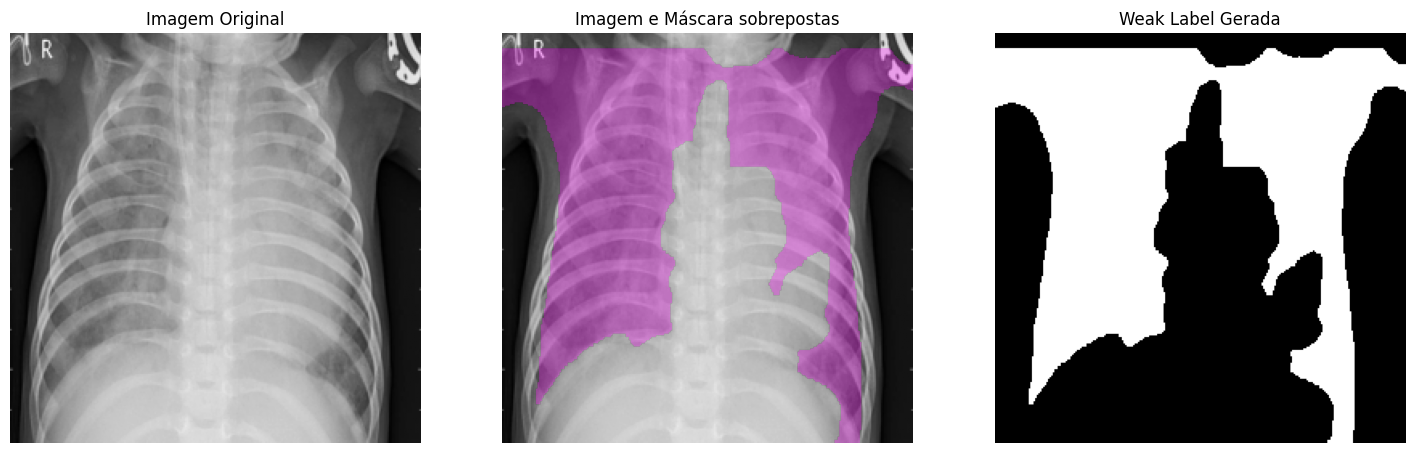

QC_2 = 0.5079794526100159


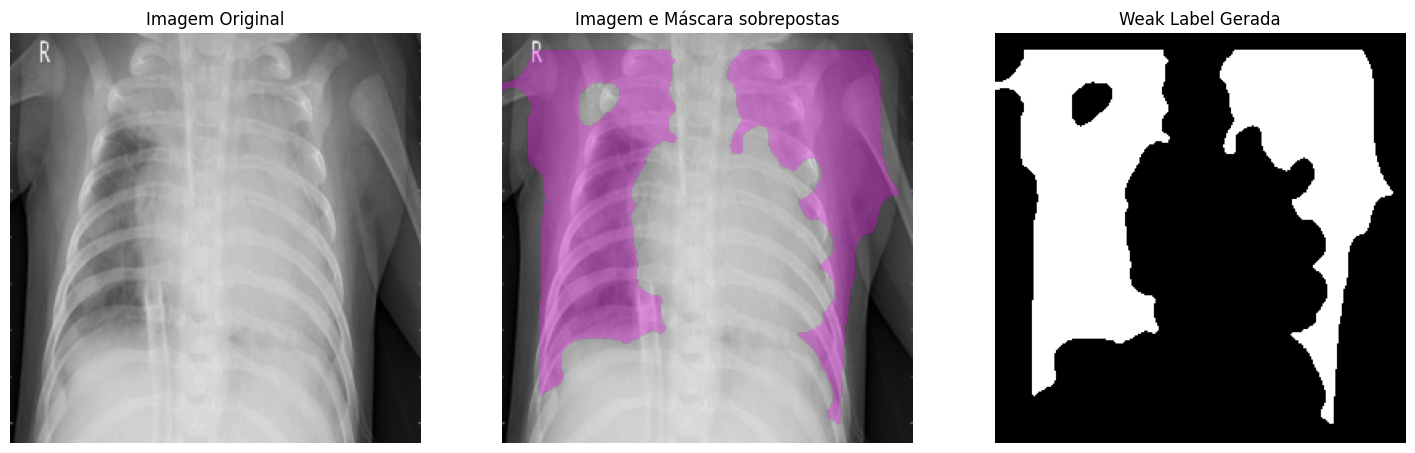

QC_3 = 0.47548189759254456


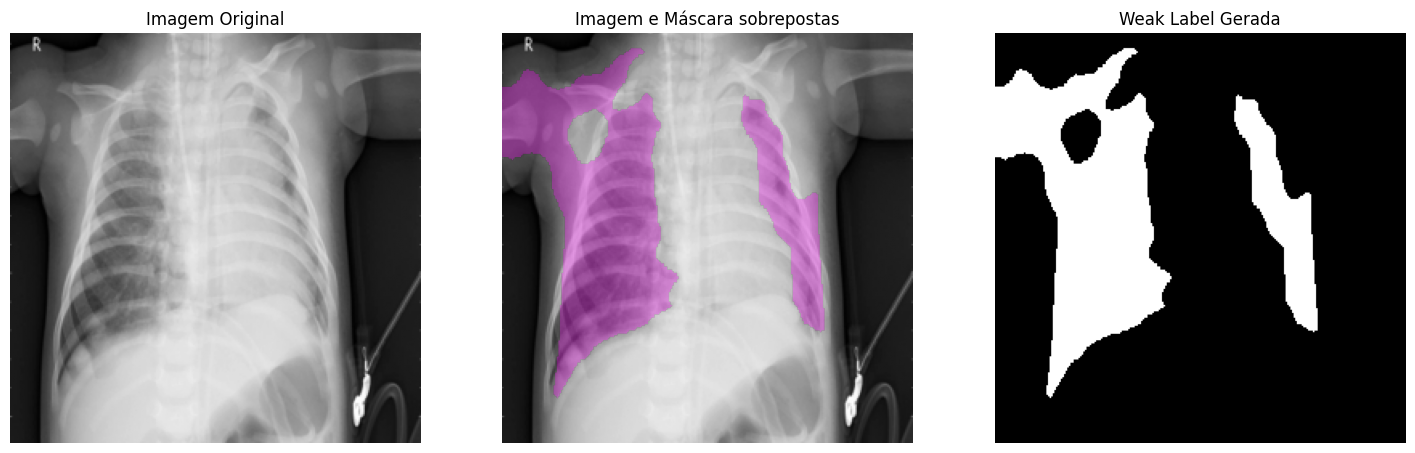

QC_4 = 0.43951329588890076


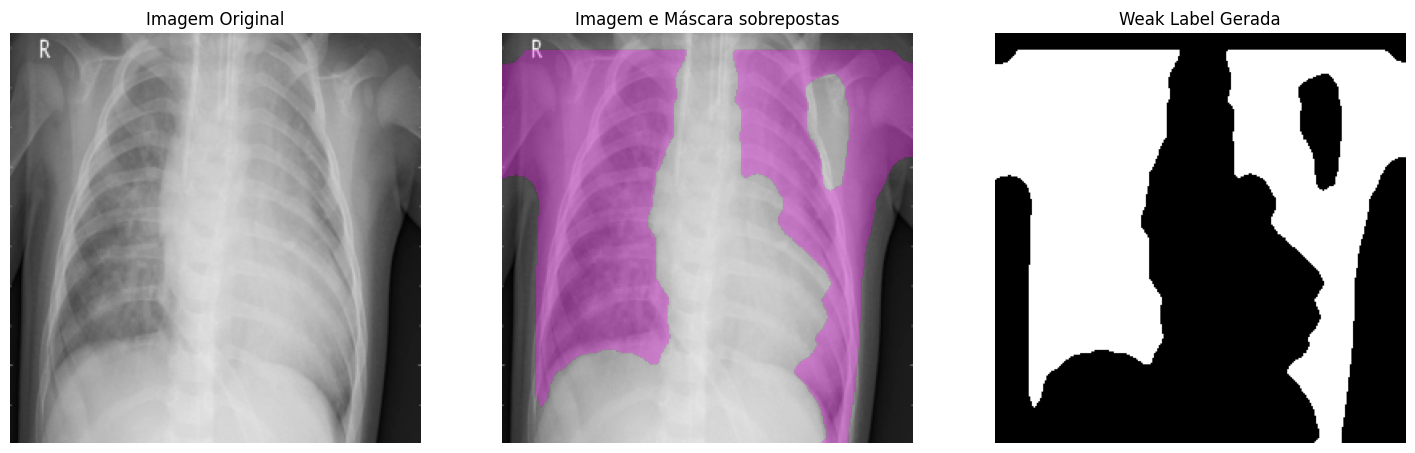

QC_5 = 0.3755219578742981


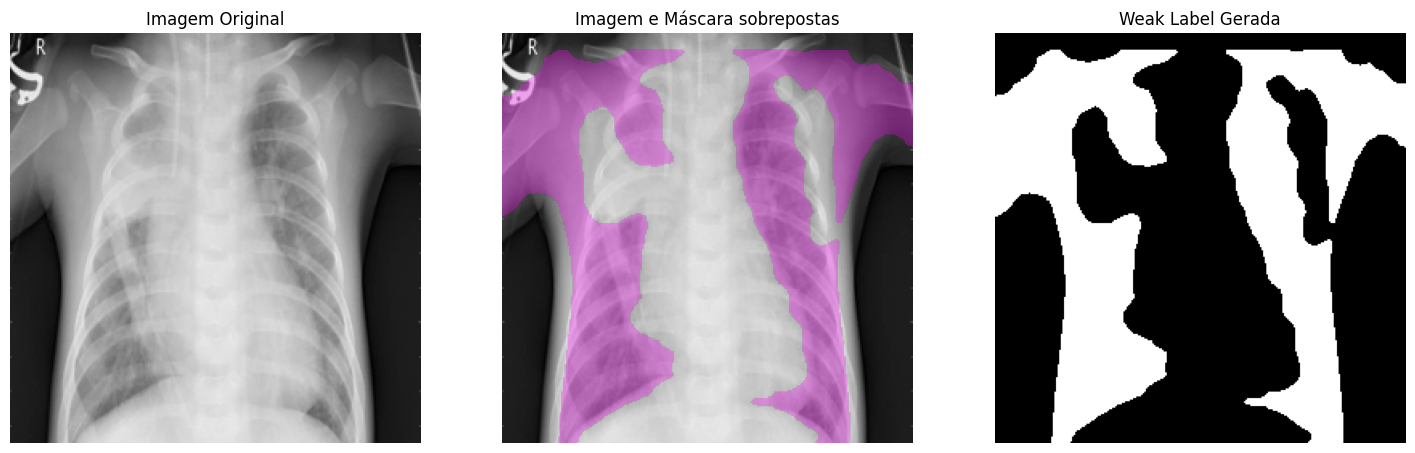

In [12]:
DATASET = SelfSegCXRDataset(image_size=(256, 256))
DATASET = Subset(DATASET, range(len(DATASET))) # Para que fosse possível executar a tempo

train_ds, test_ds = get_train_test_split(DATASET)

for i in range(5):
    img, mask, qc = train_ds[i]
    
    img, mask = img.cpu()[0], mask.cpu()[0]
    
    plt.figure(figsize=(18,6))
    plt.subplot(1,3,1)
    plt.title("Imagem Original")
    plt.imshow(img, cmap="gray")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.title("Imagem e Máscara sobrepostas")
    plt.imshow(img, cmap="gray")
    masked_overlay = np.ma.masked_where(mask == 0, mask)
    plt.imshow(masked_overlay, cmap = "spring", alpha = 0.3)
    plt.axis("off")
    
    plt.subplot(1,3,3)
    plt.title("Weak Label Gerada")
    plt.imshow(mask, cmap="gray")
    plt.axis("off")

    print(f"QC_{i+1} = {qc}")
    
    plt.show()

In [13]:
len(DATASET)

40992

## Avaliação

In [14]:
# Instancia sem augmentation para avaliar puramente a heurística generate_weak_mask
eval_ds = SelfSegCXRDataset(
    dataset_path=INPUT_DIR,
    image_size=(256, 256),
    augment=None,
    max_samples=2000,
    compute_qc=True
)

eval_loader = DataLoader(eval_ds, batch_size=32, shuffle=False, num_workers=4)

all_qcs = []
sample_records = []  # Guarda (qc, image, mask) de 320 amostras para plotar depois

for batch_idx, (images, masks, qcs) in enumerate(tqdm(eval_loader, desc="Avaliando Weak Labels")):
    qcs_np = qcs.numpy()
    all_qcs.extend(qcs_np.tolist())
    
    if batch_idx < 10:
        for img, msk, score in zip(images, masks, qcs_np):
            sample_records.append((float(score), img[0].numpy(), msk[0].numpy()))

all_qcs = np.array(all_qcs)
s = pd.Series(all_qcs)

print("=== Estatísticas Descritivas do QC Score ===")
stats = {
    "Total avaliado": len(s),
    "Média": s.mean(),
    "Desvio Padrão": s.std(),
    "Mínimo": s.min(),
    "Q1 (25%)": s.quantile(0.25),
    "Mediana (50%)": s.median(),
    "Q3 (75%)": s.quantile(0.75),
    "Máximo": s.max(),
    "Falha total (QC == 0.0)": f"{(s == 0).sum()} ({(s == 0).mean() * 100:.1f}%)"
}
for k, v in stats.items():
    print(f"{k:<25}: {v:.4f}" if isinstance(v, float) else f"{k:<25}: {v}")

print("\n=== Taxa de Aprovação por Limiar ===")
for thresh in [0.40, 0.50, 0.60, 0.70, 0.75, 0.80]:
    count = (s >= thresh).sum()
    pct = (s >= thresh).mean() * 100
    print(f"QC >= {thresh:.2f} : {count:>5} amostras ({pct:5.1f}%)")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Avaliando Weak Labels:   0%|          | 0/63 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_nu

=== Estatísticas Descritivas do QC Score ===
Total avaliado           : 2000
Média                    : 0.3011
Desvio Padrão            : 0.2616
Mínimo                   : 0.0000
Q1 (25%)                 : 0.0003
Mediana (50%)            : 0.3599
Q3 (75%)                 : 0.4860
Máximo                   : 1.0000
Falha total (QC == 0.0)  : 496 (24.8%)

=== Taxa de Aprovação por Limiar ===
QC >= 0.40 :   764 amostras ( 38.2%)
QC >= 0.50 :   463 amostras ( 23.2%)
QC >= 0.60 :   266 amostras ( 13.3%)
QC >= 0.70 :   125 amostras (  6.2%)
QC >= 0.75 :    86 amostras (  4.3%)
QC >= 0.80 :    58 amostras (  2.9%)


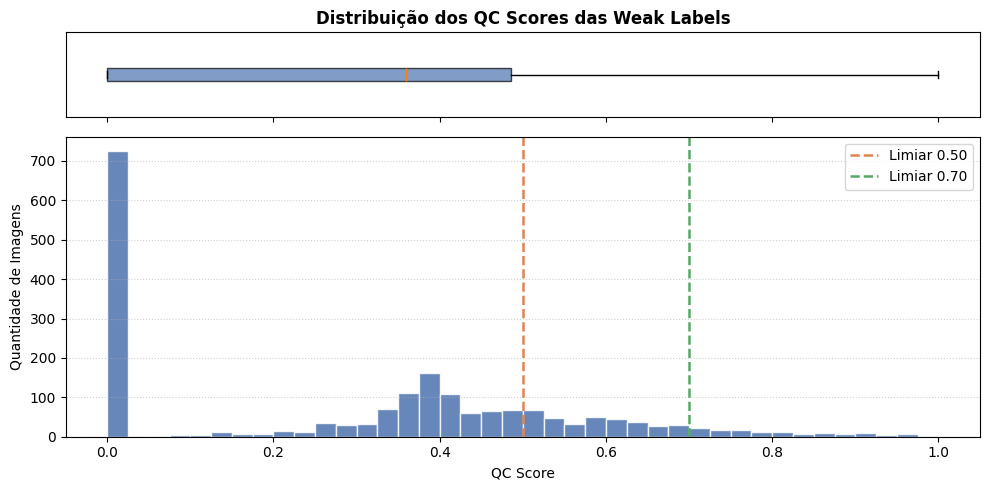

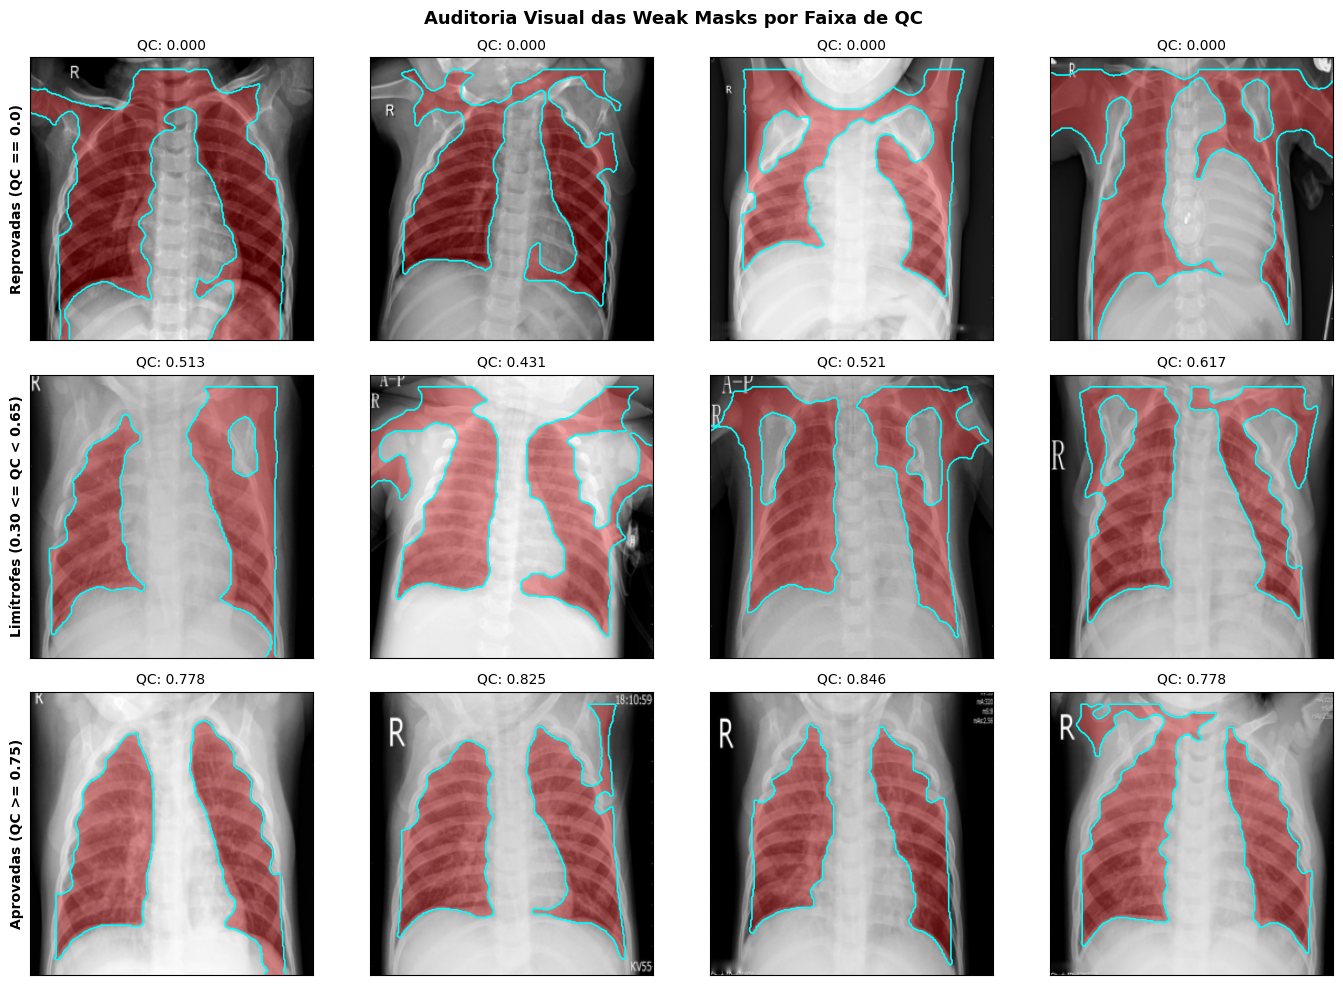

In [15]:
# --- GRÁFICO 1: Distribuição do QC Score ---
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [0.22, 0.78]}
)

ax_box.boxplot(all_qcs, vert=False, patch_artist=True, boxprops=dict(facecolor="#4C72B0", alpha=0.7))
ax_box.set_yticks([])
ax_box.set_title("Distribuição dos QC Scores das Weak Labels", fontsize=12, fontweight="bold")

ax_hist.hist(all_qcs, bins=40, range=(0, 1), color="#4C72B0", edgecolor="white", alpha=0.85)
for thresh, color in [(0.5, "#DD8452"), (0.7, "#55A868")]:
    ax_hist.axvline(thresh, color=color, linestyle="--", linewidth=1.8, label=f"Limiar {thresh:.2f}")

ax_hist.set_xlabel("QC Score")
ax_hist.set_ylabel("Quantidade de Imagens")
ax_hist.legend()
ax_hist.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# --- GRÁFICO 2: Inspeção Visual por Faixa de Qualidade ---
tiers = [
    ("Reprovadas (QC == 0.0)", [r for r in sample_records if r[0] == 0.0]),
    ("Limítrofes (0.30 <= QC < 0.65)", [r for r in sample_records if 0.30 <= r[0] < 0.65]),
    ("Aprovadas (QC >= 0.75)", [r for r in sample_records if r[0] >= 0.75]),
]

n_cols = 4
fig, axes = plt.subplots(len(tiers), n_cols, figsize=(14, 10))

for row_idx, (tier_name, items) in enumerate(tiers):
    for col_idx in range(n_cols):
        ax = axes[row_idx, col_idx]
        if col_idx < len(items):
            score, img, msk = items[col_idx]
            ax.imshow(img, cmap="gray")
            # Preenchimento semitransparente + contorno nítido da borda pulmonar
            masked_overlay = np.ma.masked_where(msk < 0.5, msk)
            ax.imshow(masked_overlay, cmap="autumn", alpha=0.30)
            ax.contour(msk, levels=[0.5], colors="cyan", linewidths=1.2)
            ax.set_title(f"QC: {score:.3f}", fontsize=10)
        else:
            ax.text(0.5, 0.5, "Sem amostras\nna faixa", ha="center", va="center", fontsize=9)
        
        ax.set_xticks([])
        ax.set_yticks([])
        if col_idx == 0:
            ax.set_ylabel(tier_name, fontsize=10, fontweight="bold")

plt.suptitle("Auditoria Visual das Weak Masks por Faixa de QC", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Registro das analises com a versão anterior

O código já foi pré-executado e substituído no notebook mas os resultados foram salvos externamente, seguem os resultados da versão V2

In [2]:
print("""
=== Estatísticas Descritivas do QC Score ===
Total avaliado : 2000
Média : 0.6074
Desvio Padrão : 0.2566
Mínimo : 0.0000
Q1 (25%) : 0.5112
Mediana (50%) : 0.6986
Q3 (75%) : 0.7909
Máximo : 0.9909
Falha total (QC == 0.0) : 12 (0.6%)

=== Taxa de Aprovação por Limiar ===
QC >= 0.40 : 1582 amostras ( 79.1%)
QC >= 0.50 : 1519 amostras ( 75.9%)
QC >= 0.60 : 1329 amostras ( 66.5%)
QC >= 0.70 : 995 amostras ( 49.8%)
QC >= 0.75 : 717 amostras ( 35.9%)
QC >= 0.80 : 449 amostras ( 22.4%)""")


=== Estatísticas Descritivas do QC Score ===
Total avaliado : 2000
Média : 0.6074
Desvio Padrão : 0.2566
Mínimo : 0.0000
Q1 (25%) : 0.5112
Mediana (50%) : 0.6986
Q3 (75%) : 0.7909
Máximo : 0.9909
Falha total (QC == 0.0) : 12 (0.6%)

=== Taxa de Aprovação por Limiar ===
QC >= 0.40 : 1582 amostras ( 79.1%)
QC >= 0.50 : 1519 amostras ( 75.9%)
QC >= 0.60 : 1329 amostras ( 66.5%)
QC >= 0.70 : 995 amostras ( 49.8%)
QC >= 0.75 : 717 amostras ( 35.9%)
QC >= 0.80 : 449 amostras ( 22.4%)


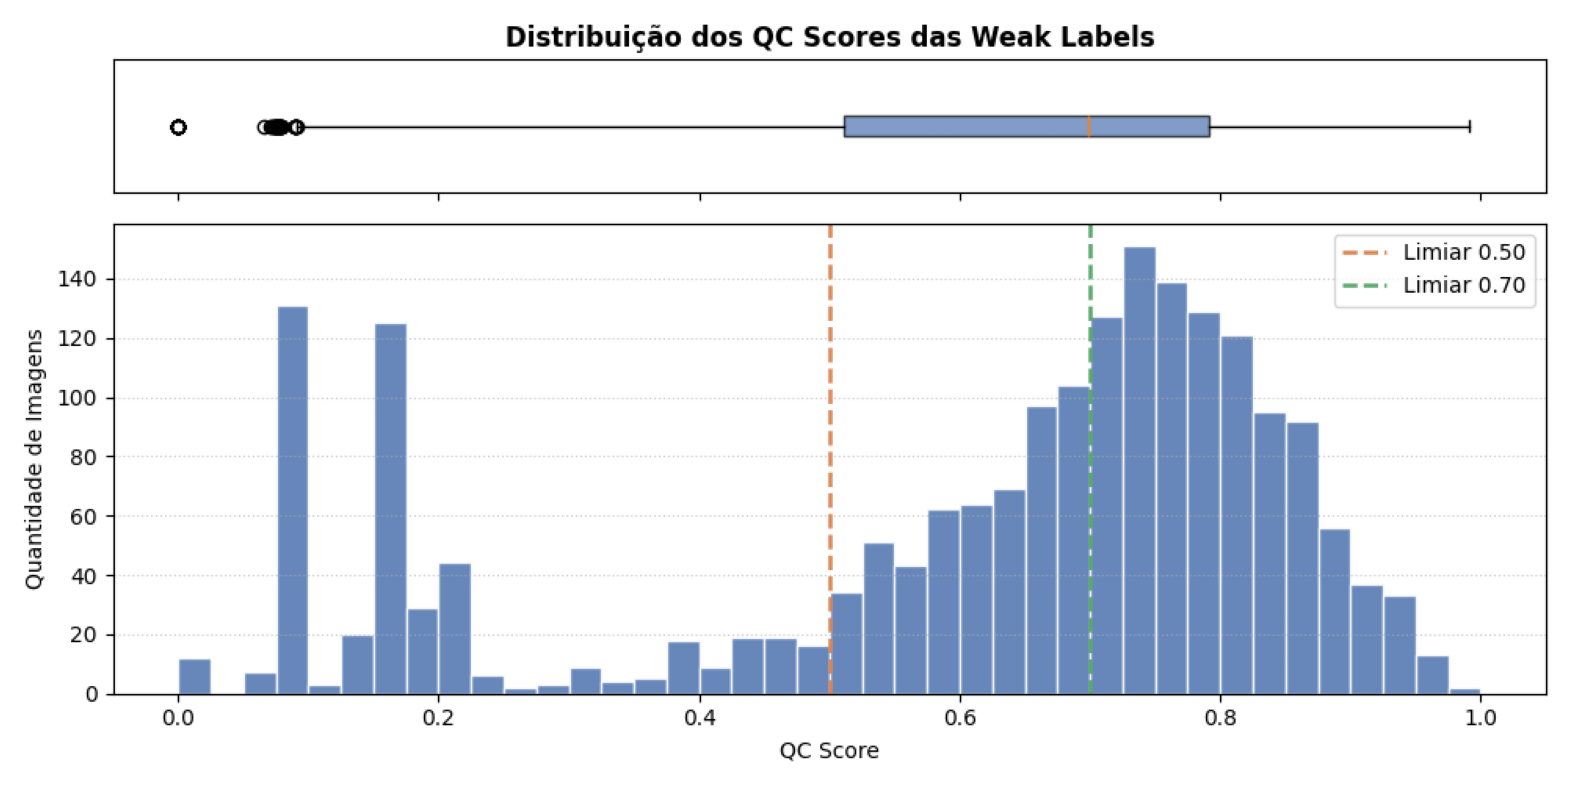

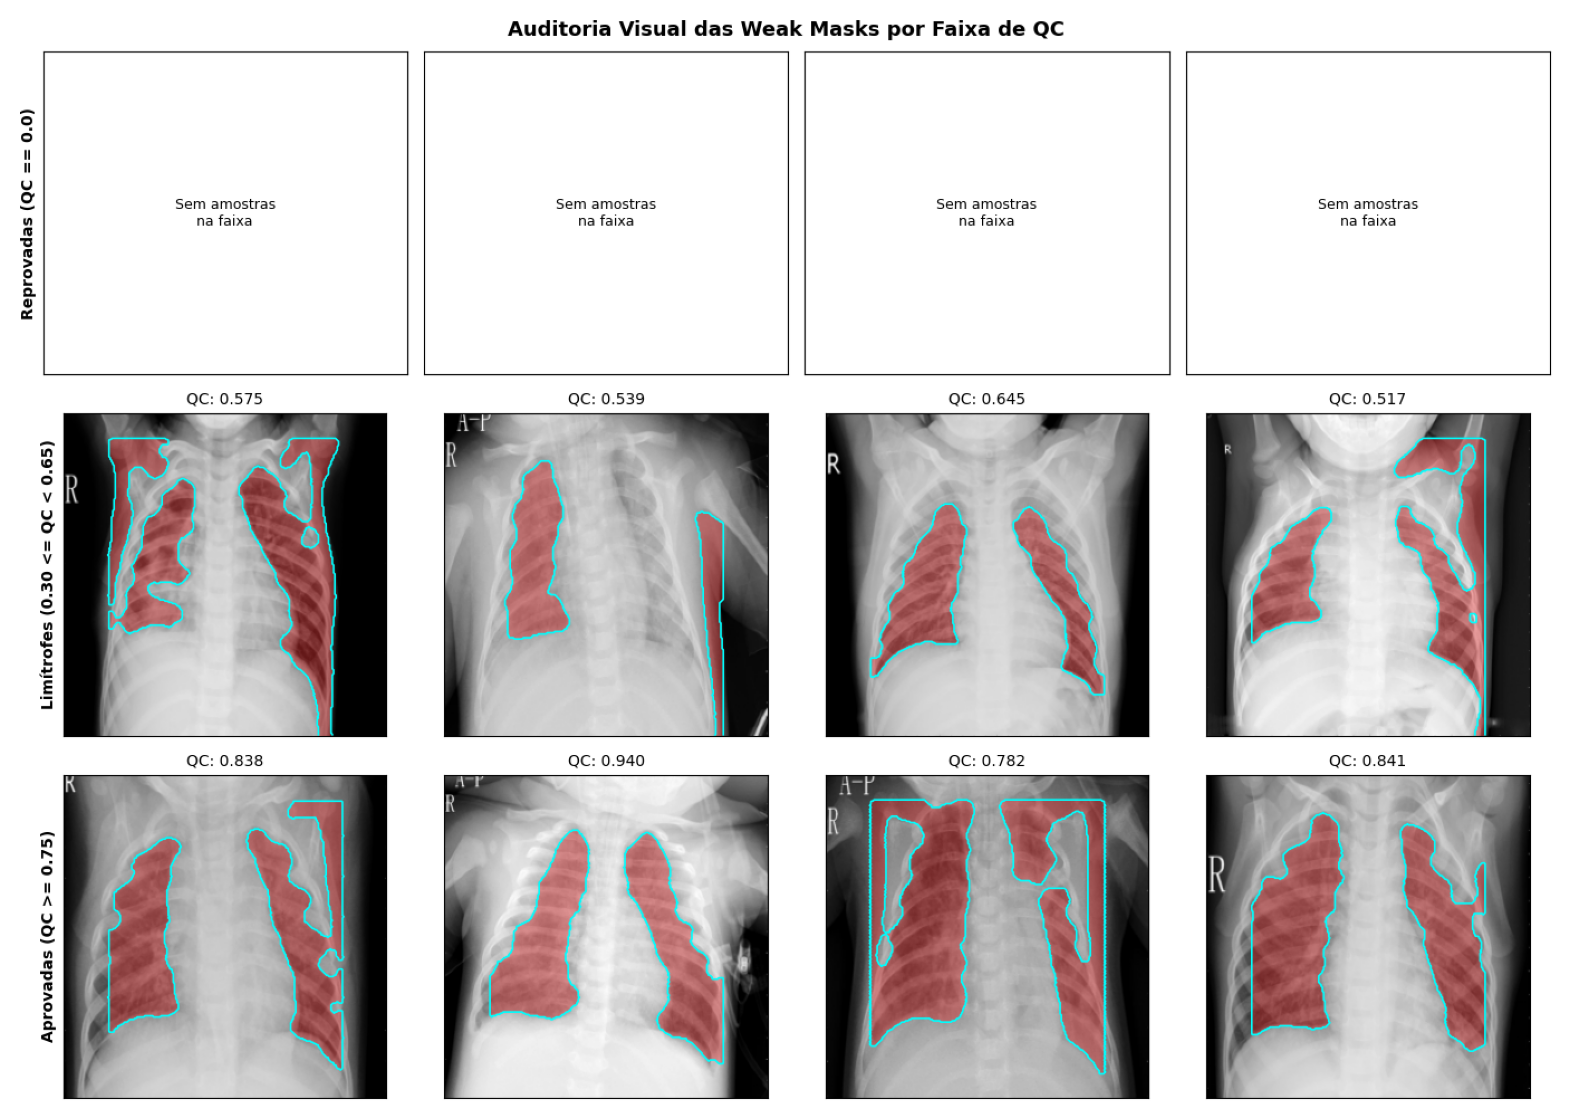

In [13]:
img1 = mpimg.imread(r"C:\Users\casti\Downloads\distribuicao_wl_v1.png")
img2 = mpimg.imread(r"C:\Users\casti\Downloads\faixas_wl_v1.png")

plt.figure(figsize=(20, 30))

plt.imshow(img1)
plt.axis("off")

plt.show()

plt.figure(figsize=(20, 30))
plt.imshow(img2)
plt.axis("off")

plt.show()

Resultados inferiores ao V3